In [ ]:
pip install iTransformer optuna

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
path = "/content/drive/MyDrive/Colab Notebooks/data/"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd

df = pd.read_csv(path+"BTCUSDT.csv", sep='|')
df = df.rename(columns={'1502942400': 'timestamp', '4261.48': 'open', '4261.48.1': 'high', '4261.48.2': 'low', '4261.48.3': 'close', '1.775183': 'btc_volume_sell', '320.390851': 'usd_volume_buy', '0.075183': 'btc_volume_buy', '7564.906851': 'usd_volume_sell', '3': 'activity'})

df

,timestamp,open,high,low,close,btc_volume_sell,usd_volume_buy,btc_volume_buy,usd_volume_sell,activity
0,1502942460,4261.48,4261.48,4261.48,4261.48,0.000000,0.000000,0.000000,0.000000,0
1,1502942520,4280.56,4280.56,4280.56,4280.56,0.261074,1117.542921,0.261074,1117.542921,2
2,1502942580,4261.48,4261.48,4261.48,4261.48,0.012008,51.171852,0.012008,51.171852,3
3,1502942640,4261.48,4261.48,4261.48,4261.48,0.140796,599.999338,0.140796,599.999338,1
4,1502942700,4261.48,4261.48,4261.48,4261.48,0.000000,0.000000,0.000000,0.000000,0
...,...,...,...,...,...,...,...,...,...,...
3927272,1739092440,97019.80,97019.80,97010.87,97010.88,2.240830,85665.477260,0.883000,217398.976800,566
3927273,1739092500,97010.88,97010.88,96958.32,96958.33,2.732930,61606.259450,0.635210,265051.749220,1807
3927274,1739092560,96958.32,96960.09,96955.60,96960.08,4.747940,322705.228800,3.328320,460349.283670,856
3927275,1739092620,96960.08,96960.09,96948.31,96948.32,1.558250,15319.539770,0.158000,151085.755800,560


##Derive volatility

In [ ]:
import numpy as np

# volatility
df['datetime'] = pd.to_datetime(df['timestamp'], unit='s')
df.set_index('datetime', inplace=True)
df['log_return'] = np.log(df['close'] / df['close'].shift(1))
window_size = 30 * 60 * 60
df['30d_volatility'] = df['log_return'].rolling(window=window_size).std() * np.sqrt(window_size)
df[['close', 'log_return', '30d_volatility']].tail(10)

# avg volume, avg buy volume, avg sell volume
df['datetime'] = pd.to_datetime(df['timestamp'], unit='s')
df.set_index('datetime', inplace=True)
df['usd_total_volume'] = df['usd_volume_buy'] + df['usd_volume_sell']
df['7d_usd_volume_buy_avg'] = df['usd_volume_buy'].rolling(window=7*24*60, center=False).mean()
df['7d_usd_volume_sell_avg'] = df['usd_volume_sell'].rolling(window=7*24*60, center=False).mean()
df['7d_usd_volume_avg'] = df['usd_total_volume'].rolling(window=7*24*60, center=False).mean()

max_vol = max(df[df['30d_volatility'].notna()]['30d_volatility'])
print(max_vol)

window = 4 * 60
#first value most important, last
df['forward_usd_volume_buy_avg'] =  df['usd_volume_buy'].ewm(span=window, adjust=False).mean()
df['forward_usd_volume_sell_avg'] =  df['usd_volume_sell'].ewm(span=window, adjust=False).mean()
df['forward_usd_volume_avg'] =  df['usd_total_volume'].ewm(span=window, adjust=False).mean()

# Calculate 1-hour price change
df['price_change_1h'] = df['close'].diff(periods=60) # Assuming data is in 1-minute intervals, 60 periods = 1 hour
df['price_change_4h'] = df['close'].diff(periods=4*60) # Assuming data is in 1-minute intervals, 60 periods = 1 hour

df['price_change_4h_tanh'] = np.tanh(df['price_change_4h'])
df['price_change_4h_volatility_tanh'] = np.tanh(df['price_change_4h'] * (max_vol - df['30d_volatility']))

df['price_change_4h_ema'] = df['price_change_4h_tanh'].ewm(span=60, adjust=False).mean()
df['price_change_4h_volatility_ema'] = df['price_change_4h_volatility_tanh'].ewm(span=60, adjust=False).mean()


df[['close','usd_volume_buy', 'forward_usd_volume_buy_avg', '7d_usd_volume_buy_avg', 'price_change_1h']] # Display price_change_1h

0.9900359831658481


,close,usd_volume_buy,forward_usd_volume_buy_avg,7d_usd_volume_buy_avg,price_change_1h
datetime,,,,,
2017-08-17 04:01:00,4261.48,0.000000,0.000000,NaN,NaN
2017-08-17 04:02:00,4280.56,1117.542921,9.274215,NaN,NaN
2017-08-17 04:03:00,4261.48,51.171852,9.621913,NaN,NaN
2017-08-17 04:04:00,4261.48,599.999338,14.521311,NaN,NaN
2017-08-17 04:05:00,4261.48,0.000000,14.400802,NaN,NaN
...,...,...,...,...,...
2025-02-09 09:14:00,97010.88,85665.477260,260452.343889,1.075860e+06,-202.14
2025-02-09 09:15:00,96958.33,61606.259450,258802.168915,1.075811e+06,-223.55
2025-02-09 09:16:00,96960.08,322705.228800,259332.484765,1.075826e+06,-266.34


## Load sentiments & technical data

In [ ]:
df_sentiments = pd.read_csv(path+"cleaned/predicted_sentiments_finbert.csv")

df_gold = pd.read_csv(path+"cleaned/GOLD_hourly.csv")
df_sp500 = pd.read_csv(path+"cleaned/SP500_hourly.csv")
df_vxx = pd.read_csv(path+"cleaned/VXX_hourly.csv")

df_tx_count = pd.read_csv(path+"cleaned/tx_count_10years.csv")
df_hashrate = pd.read_csv(path+"cleaned/hashrate_10years.csv")

df_sentiments['datetime'] = pd.to_datetime(df_sentiments['timestamp'], unit='s')
df_sentiments.set_index('datetime', inplace=True)
df_sentiments.drop('timestamp', axis=1, inplace=True)

df_gold['datetime'] = pd.to_datetime(df_gold['timestamp'], unit='s')
df_gold.set_index('datetime', inplace=True)
df_gold.drop('timestamp', axis=1, inplace=True)

df_sp500['datetime'] = pd.to_datetime(df_sp500['timestamp'], unit='s')
df_sp500.set_index('datetime', inplace=True)
df_sp500.drop('timestamp', axis=1, inplace=True)

df_vxx['datetime'] = pd.to_datetime(df_vxx['timestamp'], unit='s')
df_vxx.set_index('datetime', inplace=True)
df_vxx.drop('timestamp', axis=1, inplace=True)

In [ ]:
if not pd.api.types.is_datetime64_any_dtype(df_hashrate.index):
    if 'hour' in df_hashrate.columns:
        df_hashrate['datetime'] = pd.to_datetime(df_hashrate['hour'], utc=True)
        df_hashrate.set_index('datetime', inplace=True)
        df_hashrate.drop('hour', axis=1, inplace=True)
    else:
        print("Error: 'hour' column not found to set as DatetimeIndex.")

if pd.api.types.is_datetime64_any_dtype(df_hashrate.index):
    df_hashrate = df_hashrate.interpolate(method='time', limit_direction='both')
    display(df_hashrate)
else:
    print("Interpolation skipped: df_hashrate does not have a DatetimeIndex.")

,blocks_mined,est_hashrate
datetime,,
2015-10-01 00:00:00+00:00,6,9.256395e+06
2015-10-01 01:00:00+00:00,2,1.124337e+07
2015-10-01 02:00:00+00:00,4,8.130558e+06
2015-10-01 03:00:00+00:00,6,7.844689e+06
2015-10-01 04:00:00+00:00,7,1.146635e+07
...,...,...
2025-09-27 12:00:00+00:00,8,1.188918e+07
2025-09-27 13:00:00+00:00,3,1.095655e+07
2025-09-27 14:00:00+00:00,3,1.782144e+07


In [ ]:
if not pd.api.types.is_datetime64_any_dtype(df_tx_count.index):
    if 'hour' in df_tx_count.columns:
        df_tx_count['datetime'] = pd.to_datetime(df_tx_count['hour'], utc=True)
        df_tx_count.set_index('datetime', inplace=True)
        df_tx_count.drop('hour', axis=1, inplace=True)
    else:
        print("Error: 'hour' column not found to set as DatetimeIndex.")

if pd.api.types.is_datetime64_any_dtype(df_tx_count.index):
    df_tx_count = df_tx_count.interpolate(method='time', limit_direction='both')
    display(df_tx_count)
else:
    print("Interpolation skipped: df_tx_count does not have a DatetimeIndex.")

,tx_count
datetime,
2024-08-31 15:00:00+00:00,43007
2024-08-31 00:00:00+00:00,46304
2024-08-30 00:00:00+00:00,45914
2024-08-30 01:00:00+00:00,19682
2024-08-29 08:00:00+00:00,33163
...,...
2017-07-07 13:00:00+00:00,13267
2017-07-06 00:00:00+00:00,7837
2017-07-02 07:00:00+00:00,7285


In [ ]:
# Ensure both dataframes have a timezone-aware datetime index before merging
if df.index.tzinfo is None:
    df.index = df.index.tz_localize('UTC')

if df_sentiments.index.tzinfo is None:
    df_sentiments.index = df_sentiments.index.tz_localize('UTC')

if df_gold.index.tzinfo is None:
    df_gold.index = df_gold.index.tz_localize('UTC')

if df_sp500.index.tzinfo is None:
    df_sp500.index = df_sp500.index.tz_localize('UTC')

if df_vxx.index.tzinfo is None:
    df_vxx.index = df_vxx.index.tz_localize('UTC')

In [ ]:
df_hourly_sendiments = df_sentiments.resample('1h').agg({'predicted_sentiment': ['min', 'max', 'mean']})
df_hourly_sendiments = df_hourly_sendiments.fillna(0)
df_hourly_sendiments.columns = ['_'.join(col).strip() if isinstance(col, tuple) else col for col in df_hourly_sendiments.columns.values]
df_hourly_sendiments = df_hourly_sendiments.rename(columns={'predicted_sentiment_mean': 'predicted_sentiment_24h_avg'})
df_hourly_sendiments['predicted_sentiment_24h_avg'] = df_hourly_sendiments['predicted_sentiment_24h_avg'].rolling(window=24).mean()

df_hourly_sendiments = df_hourly_sendiments.fillna(0)
df_hourly_sendiments

,predicted_sentiment_min,predicted_sentiment_max,predicted_sentiment_24h_avg
datetime,,,
2019-01-03 09:00:00+00:00,0.018504,0.018504,0.000000
2019-01-03 10:00:00+00:00,0.000000,0.000000,0.000000
2019-01-03 11:00:00+00:00,0.017183,0.017183,0.000000
2019-01-03 12:00:00+00:00,-0.031884,-0.031884,0.000000
2019-01-03 13:00:00+00:00,0.015074,0.020079,0.000000
...,...,...,...
2025-03-31 10:00:00+00:00,0.000000,0.000000,0.000962
2025-03-31 11:00:00+00:00,0.000000,0.000000,0.000962
2025-03-31 12:00:00+00:00,0.006487,0.006487,0.001233


In [ ]:
# Merge df and df_sentiments on their datetime index
merged_df = df.merge(df_hourly_sendiments, left_index=True, right_index=True, how='left')

# Merge other dataframes with specific suffixes to avoid duplicate column names
merged_df = merged_df.merge(df_gold, left_index=True, right_index=True, how='left', suffixes=('', '_gold'))
merged_df = merged_df.merge(df_sp500, left_index=True, right_index=True, how='left', suffixes=('', '_sp500'))
merged_df = merged_df.merge(df_vxx, left_index=True, right_index=True, how='left', suffixes=('', '_vxx'))
merged_df = merged_df.merge(df_tx_count, left_index=True, right_index=True, how='left')
merged_df = merged_df.merge(df_hashrate, left_index=True, right_index=True, how='left')

merged_df[['close_gold', 'close_sp500', 'close_vxx']] = merged_df[['close_gold', 'close_sp500', 'close_vxx']].ffill()

display(merged_df.tail())

,timestamp,open,high,low,close,btc_volume_sell,usd_volume_buy,btc_volume_buy,usd_volume_sell,activity,...,close_sp500,volume_sp500,open_vxx,high_vxx,low_vxx,close_vxx,volume_vxx,tx_count,blocks_mined,est_hashrate
datetime,,,,,,,,,,,,,,,,,,,,,
2025-02-09 09:14:00+00:00,1739092440,97019.80,97019.80,97010.87,97010.88,2.24083,85665.47726,0.88300,217398.97680,566,...,552.335,NaN,NaN,NaN,NaN,44.06,NaN,NaN,NaN,NaN
2025-02-09 09:15:00+00:00,1739092500,97010.88,97010.88,96958.32,96958.33,2.73293,61606.25945,0.63521,265051.74922,1807,...,552.335,NaN,NaN,NaN,NaN,44.06,NaN,NaN,NaN,NaN
2025-02-09 09:16:00+00:00,1739092560,96958.32,96960.09,96955.60,96960.08,4.74794,322705.22880,3.32832,460349.28367,856,...,552.335,NaN,NaN,NaN,NaN,44.06,NaN,NaN,NaN,NaN
2025-02-09 09:17:00+00:00,1739092620,96960.08,96960.09,96948.31,96948.32,1.55825,15319.53977,0.15800,151085.75580,560,...,552.335,NaN,NaN,NaN,NaN,44.06,NaN,NaN,NaN,NaN
2025-02-09 09:18:00+00:00,1739092680,96948.31,96948.31,96940.58,96940.59,0.38811,14587.53767,0.15047,37625.53987,550,...,552.335,NaN,NaN,NaN,NaN,44.06,NaN,NaN,NaN,NaN


## Sum split for transformers

In [ ]:
merged_df.index = pd.to_datetime(merged_df.index, utc=True)

df_hourly = merged_df.resample('1h').agg({
    'price_change_1h': 'last',
    'close': 'last',
    'usd_volume_buy': 'sum',
    'usd_volume_sell': 'sum',
    'close_gold': 'last',
    'close_vxx': 'last',
    'close_sp500': 'last',
    'tx_count': 'sum',
    'blocks_mined': 'sum',
    'est_hashrate': 'mean',
    #'predicted_sentiment_min': 'min',
    #'predicted_sentiment_max': 'max',
    #'predicted_sentiment_24h_avg': 'mean'
}).dropna()


len(df_hourly)
df_hourly

,price_change_1h,close,usd_volume_buy,usd_volume_sell,close_gold,close_vxx,close_sp500,tx_count,blocks_mined,est_hashrate
datetime,,,,,,,,,,
2019-09-30 14:00:00+00:00,86.81,8201.57,1.479622e+07,2.620998e+07,14.165,23.790,272.440,21584.0,8.0,2.062409e+07
2019-09-30 15:00:00+00:00,82.28,8283.85,2.337566e+07,4.222758e+07,14.045,23.710,272.770,2779.0,1.0,1.643846e+07
2019-09-30 17:00:00+00:00,-29.23,8230.78,5.038690e+06,1.340925e+07,14.045,23.565,273.080,14150.0,5.0,8.067181e+06
2019-09-30 18:00:00+00:00,28.18,8258.96,6.928682e+06,1.355439e+07,14.095,23.700,272.960,21515.0,7.0,9.818671e+06
2019-09-30 19:00:00+00:00,10.57,8269.53,3.306980e+06,5.958969e+06,14.095,23.730,272.710,24767.0,8.0,1.119939e+07
...,...,...,...,...,...,...,...,...,...,...
2025-02-09 05:00:00+00:00,-191.31,97029.28,8.718456e+06,2.164190e+07,53.965,44.060,552.335,15417.0,5.0,8.925535e+06
2025-02-09 06:00:00+00:00,-23.39,97005.89,1.039896e+07,2.797514e+07,53.965,44.060,552.335,11215.0,8.0,1.481662e+07
2025-02-09 07:00:00+00:00,51.94,97057.83,1.169613e+07,2.107672e+07,53.965,44.060,552.335,7935.0,3.0,1.278264e+07


In [ ]:
import pandas as pd

# Select last year for validation
last_year = df_hourly.index.max() - pd.Timedelta(days=365)
train_df = df_hourly[df_hourly.index < last_year]
val_df = df_hourly[df_hourly.index >= last_year]

import numpy as np

def create_sequences(data_df, target_column, seq_length):
    X, y = [], []
    data = data_df.values # Use all columns as features
    target_data = data_df[target_column].values
    for i in range(len(data_df) - seq_length):
        X.append(data[i:i+seq_length])
        y.append(target_data[i+seq_length])
    return np.array(X), np.array(y)

seq_length = 24*7  # Use past 7 days (168 hours) to predict next hour
X_train, y_train = create_sequences(train_df, 'price_change_1h', seq_length)
X_val, y_val = create_sequences(val_df, 'price_change_1h', seq_length)


In [ ]:
import torch.nn as nn
class FeatureAttention(nn.Module):
    def __init__(self, num_features):
        super().__init__()
        self.attn = nn.Parameter(torch.zeros(num_features))

    def forward(self, x):
        weights = torch.softmax(self.attn, dim=0)
        return x * weights


## Traqnsformers

### Hyperparameter Tuning with Optuna

In [ ]:
# if torch.cuda.is_available():
#     print(torch.cuda.get_device_name(0))
#     print("Capability:", torch.cuda.get_device_capability(0))

# import os
# os.environ["PYTORCH_SDP_KERNEL"] = "math"

# import torch.nn.functional as F

# # Force fallback
# torch.backends.cuda.enable_flash_sdp(False)
# torch.backends.cuda.enable_mem_efficient_sdp(False)
# torch.backends.cuda.enable_math_sdp(True)


In [ ]:
import optuna
import torch
import torch.nn as nn
from iTransformer import iTransformer
from sklearn.model_selection import train_test_split
from torch.cuda.amp import autocast

torch.cuda.empty_cache()
device = 'cuda' if torch.cuda.is_available() else 'cpu'
num_variates = X_train.shape[-1]



def objective(trial):
    dim = trial.suggest_categorical("dim", [64,128])
    depth = trial.suggest_int("depth", 2, 6)
    heads = trial.suggest_categorical("heads", [4, 8, 16, 32])
    lr = trial.suggest_float("lr", 1e-5, 1e-2, log=True)
    batch_size = 2048 #trial.suggest_categorical("batch_size", [64, 128, 256, 512])


    device = 'cuda' if torch.cuda.is_available() else 'cpu'
    num_variates = X_train.shape[-1]
    lookback_len = seq_length
    pred_length = 1

    subset_size = 10000
    X_train_tensor_subset = torch.tensor(X_train[:subset_size], dtype=torch.float32).to(device)
    y_train_tensor_subset = torch.tensor(y_train[:subset_size], dtype=torch.float32).to(device)
    X_val_tensor = torch.tensor(X_val, dtype=torch.float32).to(device)
    y_val_tensor = torch.tensor(y_val, dtype=torch.float32).to(device)


    # Define iTransformer model with suggested hyperparameters
    #feature_attn = FeatureAttention(num_variates).to(device)
    model = iTransformer(
        num_variates = num_variates,
        lookback_len = lookback_len,
        dim = dim,
        depth = depth,
        heads = heads,
        dim_head = 32,
        pred_length = pred_length,
        num_tokens_per_variate = 1,
        use_reversible_instance_norm = True
    ).to(device)

    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
    #optimizer = torch.optim.AdamW(    list(model.parameters()) + list(feature_attn.parameters()),    lr=lr)
    loss_fn = nn.HuberLoss()

    epochs = 5
    train_data = torch.utils.data.TensorDataset(X_train_tensor_subset, y_train_tensor_subset)
    train_loader = torch.utils.data.DataLoader(train_data, batch_size=batch_size, shuffle=False)

    close_col_index = df_hourly.columns.get_loc('price_change_1h')

    for epoch in range(epochs):
        model.train()
        #feature_attn.train()
        for batch_X, batch_y in train_loader:
            optimizer.zero_grad()

            # apply feature attention
            #batch_X = feature_attn(batch_X)
            output = model(batch_X)

            output_close = output[:, :, close_col_index].squeeze()
            loss = loss_fn(output_close, batch_y)

            loss.backward()
            optimizer.step()

    model.eval()
    #feature_attn.eval()
    val_loss = 0.0
    val_data = torch.utils.data.TensorDataset(X_val_tensor, y_val_tensor)
    val_loader = torch.utils.data.DataLoader(val_data, batch_size=batch_size)

    with torch.no_grad():
        for batch_X_val, batch_y_val in val_loader:
            #batch_X_val = feature_attn(batch_X_val)
            output = model(batch_X_val)

            output_close = output[:, :, close_col_index].squeeze()
            val_loss += loss_fn(output_close, batch_y_val).item()

    avg_val_loss = val_loss / len(val_loader)
    return avg_val_loss

study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=50)

print("Best hyperparameters: ", study.best_params)

[I 2025-11-09 19:52:14,645] A new study created in memory with name: no-name-bb384364-cb65-4072-9eeb-482a160f21da


Non-A100 GPU detected, using math or mem efficient attention if input tensor is on cuda


[I 2025-11-09 19:52:24,043] Trial 0 finished with value: 704684.66875 and parameters: {'dim': 128, 'depth': 5, 'heads': 8, 'lr': 2.2068585473297176e-05}. Best is trial 0 with value: 704684.66875.
[I 2025-11-09 19:52:25,749] Trial 1 finished with value: 10094.14765625 and parameters: {'dim': 64, 'depth': 2, 'heads': 4, 'lr': 6.259277657795666e-05}. Best is trial 1 with value: 10094.14765625.
[I 2025-11-09 19:52:28,940] Trial 2 finished with value: 37480.215625 and parameters: {'dim': 64, 'depth': 4, 'heads': 4, 'lr': 0.00032095112839290203}. Best is trial 1 with value: 10094.14765625.
[I 2025-11-09 19:52:38,554] Trial 3 finished with value: 46897.41015625 and parameters: {'dim': 64, 'depth': 5, 'heads': 32, 'lr': 0.0012972212422008278}. Best is trial 1 with value: 10094.14765625.
[I 2025-11-09 19:52:41,038] Trial 4 finished with value: 3016.197412109375 and parameters: {'dim': 64, 'depth': 3, 'heads': 4, 'lr': 0.001870546456224019}. Best is trial 4 with value: 3016.197412109375.
[I 2025

Best hyperparameters:  {'dim': 64, 'depth': 2, 'heads': 4, 'lr': 0.008929166742935774}


### Train

In [ ]:
import torch
from iTransformer import iTransformer
import numpy as np # Import numpy

# Set device
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(device)
torch.cuda.empty_cache()

num_variates = X_train.shape[-1]
lookback_len = seq_length      # past hours # Corrected lookback_len
pred_length = 1        # predict next hour


# Convert numpy arrays to torch tensors
X_train_tensor = torch.tensor(X_train, dtype=torch.float32).to(device)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32).to(device)
X_val_tensor = torch.tensor(X_val, dtype=torch.float32).to(device)
y_val_tensor = torch.tensor(y_val, dtype=torch.float32).to(device)

# Define iTransformer model with best hyperparameters from the study
best_params = study.best_params
#feature_attn = FeatureAttention(num_variates).to(device)
model = iTransformer(
    num_variates = num_variates,
    lookback_len = lookback_len,
    dim = best_params['dim'],
    depth = best_params['depth'],
    heads = best_params['heads'],
    dim_head = 32,
    pred_length = pred_length,
    num_tokens_per_variate = 1,
    use_reversible_instance_norm = True
).to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr=best_params['lr'])
#optimizer = torch.optim.AdamW(list(model.parameters()) + list(feature_attn.parameters()), lr=best_params['lr'])
loss_fn = torch.nn.HuberLoss()

subset_size = len(X_train_tensor) #min(len(X_train_tensor), 50000) # Adjusted subset_size for OOM
print(len(X_train_tensor) )
X_train_tensor_subset = torch.tensor(X_train[:subset_size], dtype=torch.float32).to(device)
y_train_tensor_subset = torch.tensor(y_train[:subset_size], dtype=torch.float32).to(device)


batch_size = 2048
train_data = torch.utils.data.TensorDataset(X_train_tensor_subset, y_train_tensor_subset)
train_loader = torch.utils.data.DataLoader(train_data, batch_size=batch_size, shuffle=False)

# Gradient Accumulation
accumulation_steps = 4 # Accumulate gradients over 4 batches

close_col_index = df_hourly.columns.get_loc('price_change_1h')

cuda
37914


In [ ]:

epochs = 2000
for epoch in range(epochs):
    model.train()
    #feature_attn.train()
    total_loss = 0
    for i, (batch_X, batch_y) in enumerate(train_loader):
        #batch_X = feature_attn(batch_X)
        output = model(batch_X)
        output_price_change = output[:, :, close_col_index].squeeze()
        loss = loss_fn(output_price_change, batch_y)

        loss = loss / accumulation_steps
        loss.backward()

        if (i + 1) % accumulation_steps == 0:
            optimizer.step()
            optimizer.zero_grad()

        total_loss += loss.item() * accumulation_steps

    if len(train_loader) % accumulation_steps != 0:
        optimizer.step()
        optimizer.zero_grad()


    print(f"Epoch {epoch+1}/{epochs}, Loss: {total_loss/len(train_loader):.6f}")

# Validation
model.eval()
with torch.no_grad():
    val_pred = model(X_val_tensor).cpu().numpy().squeeze()

import matplotlib.pyplot as plt
plt.figure(figsize=(12,6))
plt.plot(y_val.cpu().numpy(), label='Actual') # Move to CPU for plotting
plt.plot(val_pred, label='Predicted')
plt.legend()
plt.title('iTransformer 1-hour Step Prediction (Last Year)')
plt.show()

created = True

Epoch 1/2000, Loss: 2549.135459
Epoch 2/2000, Loss: 977.630079
Epoch 3/2000, Loss: 445.782117
Epoch 4/2000, Loss: 294.176591
Epoch 5/2000, Loss: 233.481862
Epoch 6/2000, Loss: 197.110328
Epoch 7/2000, Loss: 177.925378
Epoch 8/2000, Loss: 183.875390
Epoch 9/2000, Loss: 198.862386
Epoch 10/2000, Loss: 176.478608
Epoch 11/2000, Loss: 156.425887
Epoch 12/2000, Loss: 154.494091
Epoch 13/2000, Loss: 155.402554
Epoch 14/2000, Loss: 153.022364
Epoch 15/2000, Loss: 148.796869
Epoch 16/2000, Loss: 145.800568
Epoch 17/2000, Loss: 141.480697
Epoch 18/2000, Loss: 140.871246
Epoch 19/2000, Loss: 140.245353
Epoch 20/2000, Loss: 141.412761
Epoch 21/2000, Loss: 141.314983
Epoch 22/2000, Loss: 142.150824
Epoch 23/2000, Loss: 140.857553
Epoch 24/2000, Loss: 136.146194
Epoch 25/2000, Loss: 135.349837
Epoch 26/2000, Loss: 134.581967
Epoch 27/2000, Loss: 135.939263
Epoch 28/2000, Loss: 135.900207
Epoch 29/2000, Loss: 135.827524
Epoch 30/2000, Loss: 134.614361
Epoch 31/2000, Loss: 136.399803
Epoch 32/2000, L

KeyboardInterrupt: 

In [ ]:
# best_params = study.best_params # Make sure best_params is accessible here
model_path = "_".join([f"{key}-{value}" for key, value in best_params.items()])
torch.save(model.state_dict(), model_path)
print(f"Model saved to {model_path}")

Model saved to dim-64_depth-2_heads-4_lr-0.008929166742935774


## Load model

In [ ]:
import os
import torch
from iTransformer import iTransformer

# try:
#   created
# except:
model_path = 'dim-128_depth-2_heads-8_lr-0.005811365898162193'
device = 'cuda' if torch.cuda.is_available() else 'cpu'

loaded_model = iTransformer(
    num_variates = 10, # Assuming num_variates is available
    lookback_len = 24*7, # Assuming seq_length is available
    dim = 128,
    depth = 2,
    heads = 8,
    dim_head = 32,
    pred_length = 1, # Assuming pred_length is available
    num_tokens_per_variate = 1, # Assuming num_tokens_per_variate is fixed
    use_reversible_instance_norm = True # Ensure this matches the saved model's config
).to(device) # Assuming device is available


loaded_model.load_state_dict(torch.load(model_path, map_location=torch.device(device)))
loaded_model.eval() # Set the loaded model to evaluation mode
model = loaded_model

X_val_tensor = torch.tensor(X_val, dtype=torch.float32).to(device)

print(f"Model loaded from {model_path}")

## Check results

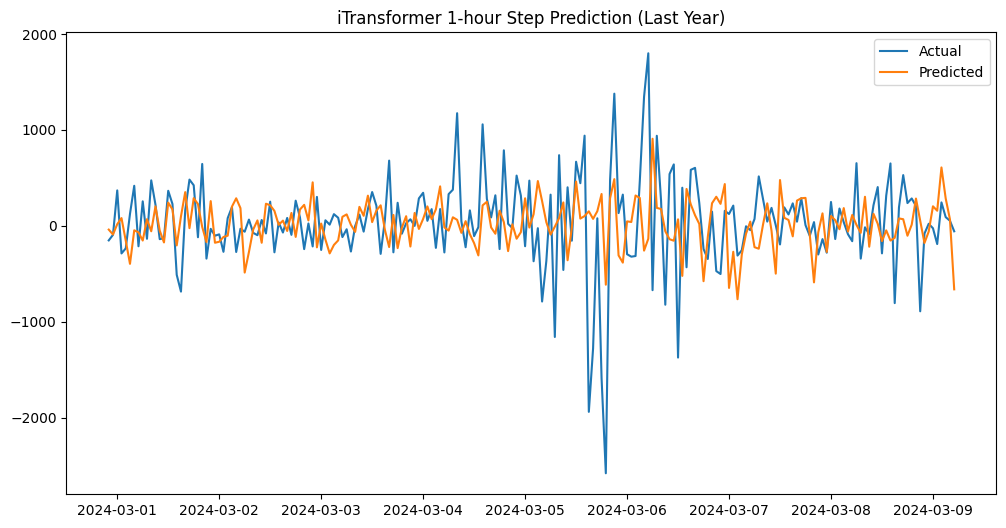

[array([ -63.61,   45.27,  -31.19, ...,   51.94,   28.17, -285.83]),
 array([  60.206127, -156.14304 , -156.34048 , ...,  -69.82382 ,
        -386.9203  , -107.088715], dtype=float32)]

In [ ]:
# Validation
model.eval()
with torch.no_grad():
    #batch_X = feature_attn(X_val_tensor)
    val_pred = model(X_val_tensor).cpu().numpy().squeeze()


# Select the prediction for the 'close' price
# This assumes the order of columns in X_val is the same as df_hourly
close_col_index = df_hourly.columns.get_loc('price_change_1h')
val_pred_1h_change = val_pred[:, close_col_index]


import matplotlib.pyplot as plt
plt.figure(figsize=(12,6))
# Use the datetime index from df_hourly for the x-axis
plt.plot(df_hourly.index[len(df_hourly)-len(y_val):][300:500], y_val[300:500], label='Actual')
plt.plot(df_hourly.index[len(df_hourly)-len(val_pred_1h_change):][300:500], val_pred_1h_change[300:500], label='Predicted')
plt.legend()
plt.title('iTransformer 1-hour Step Prediction (Last Year)')
plt.show()

[y_val, val_pred_1h_change]

In [ ]:
del X_train_tensor
del y_train_tensor
del X_val_tensor
del y_val_tensor
torch.cuda.empty_cache()

In [ ]:
import pandas as pd


val_pred_ex = val_pred[:, close_col_index]
close_price = df_hourly['close'][len(df_hourly['close'])-len(y_val):]
comparison_df = pd.DataFrame({'Actual': y_val, 'Predicted': val_pred_ex, 'Diff:':val_pred_ex-y_val, 'close_price':close_price})
comparison_df['Actual_vs_Previous_Actual'] = comparison_df['Actual'].diff()
display(comparison_df)

,Actual,Predicted,Diff:,close_price,Actual_vs_Previous_Actual
datetime,,,,,
2024-02-17 09:00:00+00:00,-63.61,60.206127,123.816127,51676.40,NaN
2024-02-17 10:00:00+00:00,45.27,-156.143036,-201.413036,51721.67,108.88
2024-02-17 11:00:00+00:00,-31.19,-156.340485,-125.150485,51690.48,-76.46
2024-02-17 12:00:00+00:00,20.62,163.889343,143.269343,51711.10,51.81
2024-02-17 13:00:00+00:00,-522.29,-7.772266,514.517734,51188.81,-542.91
...,...,...,...,...,...
2025-02-09 05:00:00+00:00,-191.31,-178.577515,12.732485,97029.28,-111.90
2025-02-09 06:00:00+00:00,-23.39,-438.889008,-415.499008,97005.89,167.92
2025-02-09 07:00:00+00:00,51.94,-69.823822,-121.763822,97057.83,75.33


### Backtest - simple treshold buy/sell

/tmp/ipython-input-3500332255.py:14: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  predicted_price = hourly_price[i-1] + predicted_changes[i]
/tmp/ipython-input-3500332255.py:15: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  predicted_pct_change = (predicted_price - hourly_price[i-1]) / hourly_price[i-1]
/tmp/ipython-input-3500332255.py:16: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  actual_pct_change = (hourly_price[i] - hourly_p

Optimal Profit Threshold: 0.720%
12090.797684681329


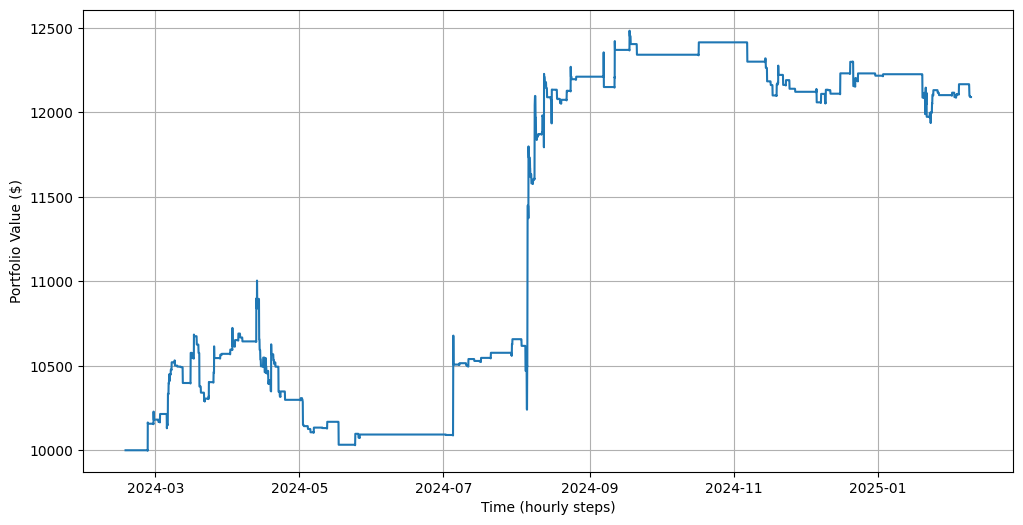

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def backtest_profit_threshold(hourly_price, predicted_changes, initial_capital=10000, threshold=0.01, transaction_cost_pct=0.1):
    capital = initial_capital
    portfolio_values = [capital]
    position = 0  # 1 = long, -1 = short
    entry_price = 0  # price at which position was opened
    threshold /= 100
    transaction_cost = transaction_cost_pct / 100

    for i in range(1, len(hourly_price)):
        predicted_price = hourly_price[i-1] + predicted_changes[i]
        predicted_pct_change = (predicted_price - hourly_price[i-1]) / hourly_price[i-1]
        actual_pct_change = (hourly_price[i] - hourly_price[i-1]) / hourly_price[i-1]

        if position != 0:
             capital *= (1 + position * actual_pct_change)

        if position == 0:
            if predicted_pct_change > threshold:
                position = 1
                entry_price = hourly_price[i-1]
                capital *= (1 - transaction_cost) # Subtract transaction cost
            elif predicted_pct_change < -threshold:
                position = -1
                entry_price = hourly_price[i-1]
                capital *= (1 - transaction_cost) # Subtract transaction cost

        elif position == 1:
            if actual_pct_change < threshold: # Exit condition
                position = 0
        elif position == -1:
            if actual_pct_change > -threshold: # Exit condition
                position = 0


        portfolio_values.append(capital)

    return portfolio_values


best_threshold = 0
initial_capital = 10000
best_final_capital = initial_capital
fixed_transaction_cost_pct = 0.0275

for threshold in np.arange(0.01, 1.0, 0.01):
    portfolio_values = backtest_profit_threshold(close_price, val_pred_1h_change, initial_capital, threshold, fixed_transaction_cost_pct)
    if portfolio_values[-1] > best_final_capital:
        best_final_capital = portfolio_values[-1]
        best_threshold = threshold

print(f"Optimal Profit Threshold: {best_threshold:.3f}%")

portfolio_history_optimal = backtest_profit_threshold(close_price, val_pred_1h_change, initial_capital, best_threshold, fixed_transaction_cost_pct)
print(portfolio_history_optimal[-1])

import matplotlib.pyplot as plt

# Get the datetime index corresponding to the length of portfolio_history_optimal
plot_index = df_hourly.index[len(df_hourly)-len(portfolio_history_optimal):]

plt.figure(figsize=(12, 6))
plt.plot(plot_index, portfolio_history_optimal) # Use plot_index for the x-axis
#plt.title(f'Portfolio Value Over Time (Buy Threshold: {best_threshold:.2f}%, Transaction Cost: {fixed_transaction_cost_pct}%)')
plt.xlabel('Time (hourly steps)')
plt.ylabel('Portfolio Value ($)')
plt.grid(True)
plt.show()

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def backtest_profit_threshold(hourly_price,
                              predicted_changes,
                              initial_capital=10000,
                              threshold=0.01,
                              vol_window=24,
                              target_risk_per_trade=0.5,
                              transaction_cost=0.1,
                              min_size=0.05,
                              max_size=1.0):
    threshold /= 100.0
    target_risk_per_trade /= 100.0
    transaction_cost /= 100.0
    prices = np.asarray(hourly_price)
    preds = np.asarray(predicted_changes)

    # Realized volatility (rolling standard deviations of returns)
    returns = np.diff(prices) / prices[:-1]
    vol_series = pd.Series(returns).rolling(vol_window).std().to_numpy()
    vol_series = np.concatenate([[0], vol_series])

    capital = initial_capital
    portfolio_values = [capital]

    position = 0          # 1 long, -1 short, 0 - no position
    position_size = 0.0   # fraction of capital
    entry_price = 0.0

    def size_from_vol(v):
        if np.isnan(v) or v < 1e-8:
            v = 0.01  # fallback volatility
        raw = target_risk_per_trade / v

        res = float(np.clip(raw, min_size, max_size)) # do not exceed min/max of position size
        #print(f'v: {v} raw: {raw} res: {res}')
        return res

    for i in range(1, len(prices)):
        predicted_price = prices[i-1] + preds[i]
        predicted_pct_change = (predicted_price - prices[i-1]) / prices[i-1]

        actual_pct_change = (prices[i] - prices[i-1]) / prices[i-1]

        if position != 0:
            capital *= (1 + position * position_size * actual_pct_change)

        if position == 0:
            if predicted_pct_change > threshold:
                position = 1
                position_size = size_from_vol(vol_series[i-1])
                entry_price = prices[i-1]
                capital = capital - (position_size * capital * transaction_cost)
            elif predicted_pct_change < -threshold:
                position = -1
                position_size = size_from_vol(vol_series[i-1])
                entry_price = prices[i-1]
                capital = capital - (position_size* capital * transaction_cost)

        elif position == 1:
            if actual_pct_change < threshold:
                position = 0
                position_size = 0.0

        elif position == -1:
            if actual_pct_change > -threshold:
                position = 0
                position_size = 0.0

        portfolio_values.append(capital)

    return portfolio_values


#best_threshold = 0
best_target_risk = 0
initial_capital = 10000
best_final_capital = initial_capital

# Iterate through thresholds and target_risk_per_trade
for threshold in np.arange(0.00, 1.01, 0.01):
    for target_risk in np.arange(0.0, 2.50, 0.01):
        print(f"Testing Threshold: {best_threshold:.2f}%, Target Risk: {target_risk:.2f}%") # Print progress
        portfolio_values = backtest_profit_threshold(
            close_price,
            val_pred_1h_change,
            initial_capital,
            threshold=threshold,
            vol_window=24,
            target_risk_per_trade=target_risk,
            transaction_cost=fixed_transaction_cost_pct
        )
        if portfolio_values[-1] > best_final_capital:
            best_final_capital = portfolio_values[-1]
            best_threshold = threshold
            best_target_risk = target_risk

print(f"Optimal Profit Threshold: {best_threshold:.2f}%")
print(f"Optimal Target Risk Per Trade: {best_target_risk:.2f}%")
print(f"Final Capital with Optimal Parameters: ${best_final_capital:.2f}")


# Run backtest with optimal parameters for plotting
portfolio_history_optimal = backtest_profit_threshold(
    close_price,
    val_pred_1h_change,
    initial_capital,
    threshold=best_threshold,
    vol_window=24,
    target_risk_per_trade=best_target_risk,
    transaction_cost=fixed_transaction_cost_pct
)

print(portfolio_history_optimal[-1])
print(f"\n Target Risk: {best_target_risk:.2f}")


plt.figure(figsize=(12, 6))
plot_index = df_hourly.index[len(df_hourly)-len(portfolio_history_optimal):]
plt.plot(plot_index, portfolio_history_optimal) # Use plot_index for the x-axis
#plt.title(f'Portfolio Value Over Time (Threshold: {best_threshold:.2f}%, Target Risk: {best_target_risk:.2f}%)')
plt.xlabel('Time (hourly steps)')
plt.ylabel('Portfolio Value ($)')
plt.grid(True)
plt.show()

Streaming output truncated to the last 5000 lines.
Testing Threshold: 0.72%, Target Risk: 0.20%
Testing Threshold: 0.72%, Target Risk: 0.21%
Testing Threshold: 0.72%, Target Risk: 0.22%
Testing Threshold: 0.72%, Target Risk: 0.23%
Testing Threshold: 0.72%, Target Risk: 0.24%
Testing Threshold: 0.72%, Target Risk: 0.25%
Testing Threshold: 0.72%, Target Risk: 0.26%
Testing Threshold: 0.72%, Target Risk: 0.27%
Testing Threshold: 0.72%, Target Risk: 0.28%
Testing Threshold: 0.72%, Target Risk: 0.29%
Testing Threshold: 0.72%, Target Risk: 0.30%
Testing Threshold: 0.72%, Target Risk: 0.31%
Testing Threshold: 0.72%, Target Risk: 0.32%
Testing Threshold: 0.72%, Target Risk: 0.33%
Testing Threshold: 0.72%, Target Risk: 0.34%
Testing Threshold: 0.72%, Target Risk: 0.35%
Testing Threshold: 0.72%, Target Risk: 0.36%
Testing Threshold: 0.72%, Target Risk: 0.37%
Testing Threshold: 0.72%, Target Risk: 0.38%
Testing Threshold: 0.72%, Target Risk: 0.39%
Testing Threshold: 0.72%, Target Risk: 0.40%
Test

In [ ]:
def backtest_ts_momentum(prices,
                         predicted_changes=None,
                         mode='momentum_only',
                         lookback=24,
                         vol_window=24,
                         target_risk_per_trade=0.5,
                         signal_strength_threshold=0.1,
                         min_size=0.05,
                         max_size=1.0,
                         initial_capital=10000,
                         hold_hours=1,
                         transaction_cost_pct=0.1):

    trades = 0
    trade_times = []  # Track when trades happen
    trade_values = []  # Track portfolio value at trade time

    prices = np.asarray(prices, float)
    n = len(prices)
    if n < lookback + 2:
        raise ValueError(f"Not enough data for lookback window of {lookback}. Need at least {lookback + 2} data points, but only have {n}.")


    target_risk_per_trade /= 100.0
    transaction_cost = transaction_cost_pct / 100.0
    signal_strength_threshold /= 100.0

    roll_ret = np.full(n, np.nan)
    if(mode == 'momentum_only'):
        for i in range(lookback, n):
            roll_ret[i] = prices[i-1] / prices[i - 1 - lookback] - 1.0
    elif(mode == 'prediction_only'):
        for i in range(lookback, n):
            predicted_price = predicted_changes[i] + prices[i-1]
            #print(f"{predicted_price} - {prices[i]} : {predicted_changes[i]}")
            roll_ret[i] = predicted_price / prices[i - 1 - lookback] - 1.0
            #print(f"{predicted_price} - {roll_ret[i]} : {prices[i - 1 - lookback]}")

    returns = np.diff(prices) / prices[:-1]
    vol_series = pd.Series(returns).rolling(vol_window).std().to_numpy()
    vol_series = np.concatenate([[0], vol_series])

    def size_from_vol(v):
        if np.isnan(v) or v < 1e-8:
            v = 0.01
        raw = target_risk_per_trade / v
        return float(np.clip(raw, min_size, max_size))

    capital = initial_capital
    portfolio_vals = [capital]

    position = 0
    position_size = 0.0
    bars_in_position = 0

    for i in range(1, n):
        ret = (prices[i] - prices[i-1]) / prices[i-1]
        if position != 0:
            capital *= (1 + position * position_size * ret)

        mom_sign = 0
        if not np.isnan(roll_ret[i-1]):
            if roll_ret[i-1] > 0:
                mom_sign = 1
            elif roll_ret[i-1] < 0:
                mom_sign = -1

        if abs(roll_ret[i-1]) > signal_strength_threshold:
            desired = mom_sign
        else:
            desired = 0

        exit_condition = False
        if position != 0:
            bars_in_position += 1
            if desired == 0 or desired != position or bars_in_position >= hold_hours:
                exit_condition = True

        if exit_condition:
            trades += 1
            position = 0
            position_size = 0.0
            bars_in_position = 0

        if position == 0 and desired != 0:
            position = desired
            position_size = size_from_vol(vol_series[i-1])
            bars_in_position = 0
            capital -= (position_size * capital * transaction_cost)
            trade_times.append(i)
            trade_values.append(capital)

        portfolio_vals.append(capital)

    #print(trades)
    return capital, portfolio_vals, trade_times, trade_values

In [ ]:
lookback_range = range(1, 24*7, 1)
hold_hours_range = range(1, 24*7, 1)
signal_strength_thresholds = np.arange(0.1, 1.0, 0.1)

best_lookback = 0
best_hold_hours = 0
best_signal_strength_threshold = 0
#best_target_risk = 0
initial_capital_opt = 10000
best_final_capital_opt = initial_capital_opt

for lookback in lookback_range:
  for hold_hours in hold_hours_range:
    for signal_strength_threshold in signal_strength_thresholds:
      try:
          final_capital, _, _, _ = backtest_ts_momentum(
              close_price,
              predicted_changes=val_pred_1h_change,
              mode='prediction_only',
              lookback=lookback,
              vol_window=24,
              hold_hours=hold_hours,
              target_risk_per_trade=best_target_risk,
              signal_strength_threshold=signal_strength_threshold,
              transaction_cost_pct=fixed_transaction_cost_pct
          )
          if final_capital > best_final_capital_opt:
              best_final_capital_opt = final_capital
              best_lookback = lookback
              best_hold_hours = hold_hours
              best_signal_strength_threshold = signal_strength_threshold
              #best_target_risk = target_risk
      except ValueError as e:
            print(f"Skipping Lookback: {lookback} hours, Target Risk: {target_risk:.2f}% due to error: {e}")


print(f"\n Optimal best_lookback: {best_lookback}")
print(f"\n Optimal best_hold_hours: {best_hold_hours}")
print(f"\n Optimal best_signal_strength_threshold: {best_signal_strength_threshold}")
print(f"\n best_final_capital_opt: {best_final_capital_opt}")
#print(f"Optimal Target Risk Per Trade: {best_target_risk:.2f}%")
#print(f"Final Capital with Optimal Parameters and {fixed_transaction_cost_pct_opt}% Transaction Cost: ${best_final_capital_opt:.2f}")


final_capital_optimal, portfolio_history_optimal, _, _ = backtest_ts_momentum(
    close_price,
    predicted_changes=val_pred_1h_change,
    mode='prediction_only',
    lookback=best_lookback,
    hold_hours=best_hold_hours,
    vol_window=24,
    target_risk_per_trade=best_target_risk,
    signal_strength_threshold=best_signal_strength_threshold,
    transaction_cost_pct=fixed_transaction_cost_pct
)

final_mom, hist_mom, _, _ = backtest_ts_momentum(
    close_price,
    predicted_changes=None,
    mode='momentum_only',
    lookback=best_lookback,
    hold_hours=best_hold_hours,
    vol_window=24,
    target_risk_per_trade=best_target_risk,
    signal_strength_threshold=best_signal_strength_threshold,
    transaction_cost_pct=fixed_transaction_cost_pct
)


plt.figure(figsize=(12,6))
plot_index_optimal = df_hourly.index[len(df_hourly)-len(portfolio_history_optimal):]
plt.plot(plot_index_optimal, portfolio_history_optimal, label=f'Prediction Only (Optimal) (Final: ${final_capital_optimal:.0f})')

plot_index_mom = df_hourly.index[len(df_hourly)-len(hist_mom):]
plt.plot(plot_index_mom, hist_mom, label=f'Momentum Only (Using Optimal Params) (Final: ${final_mom:.0f})')


#plt.title(f'Time-Series Momentum Backtesting with {fixed_transaction_cost_pct_opt}% Transaction Cost')
plt.xlabel('Time (hours)')
plt.ylabel('Portfolio Value ($)')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:

signal_strength_thresholds = np.arange(best_signal_strength_threshold-1, best_signal_strength_threshold+1, 0.01)

best_signal_strength_threshold = 0
#best_target_risk = 0
initial_capital_opt = 10000
best_final_capital_opt = initial_capital_opt

for signal_strength_threshold in signal_strength_thresholds:
    final_capital, _, _, _ = backtest_ts_momentum(
        close_price,
        predicted_changes=val_pred_1h_change,
        mode='prediction_only',
        lookback=best_lookback,
        vol_window=24,
        hold_hours=best_hold_hours,
        target_risk_per_trade=best_target_risk,
        signal_strength_threshold=signal_strength_threshold,
        transaction_cost_pct=fixed_transaction_cost_pct
    )
    if final_capital > best_final_capital_opt:
        best_final_capital_opt = final_capital
        best_signal_strength_threshold = signal_strength_threshold
        #best_target_risk = target_risk


print(f"\n Optimal best_lookback: {best_lookback}")
print(f"\n Optimal best_hold_hours: {best_hold_hours}")
print(f"\n Optimal best_signal_strength_threshold: {best_signal_strength_threshold}")
print(f"\n best_final_capital_opt: {best_final_capital_opt}")
#print(f"Optimal Target Risk Per Trade: {best_target_risk:.2f}%")
#print(f"Final Capital with Optimal Parameters and {fixed_transaction_cost_pct_opt}% Transaction Cost: ${best_final_capital_opt:.2f}")


final_capital_optimal, portfolio_history_optimal, trade_times_opt, trade_values_opt = backtest_ts_momentum(
    close_price,
    predicted_changes=val_pred_1h_change,
    mode='prediction_only',
    lookback=best_lookback,
    hold_hours=best_hold_hours,
    vol_window=24,
    target_risk_per_trade=best_target_risk,
    signal_strength_threshold=best_signal_strength_threshold,
    transaction_cost_pct=fixed_transaction_cost_pct
)

final_mom, hist_mom, trade_times_mom, trade_values_mom = backtest_ts_momentum(
    close_price,
    predicted_changes=None,
    mode='momentum_only',
    lookback=best_lookback,
    hold_hours=best_hold_hours,
    vol_window=24,
    target_risk_per_trade=best_target_risk,
    signal_strength_threshold=best_signal_strength_threshold,
    transaction_cost_pct=fixed_transaction_cost_pct
)

plt.figure(figsize=(12,6))

print(len(trade_times_opt))
print(len(trade_times_mom))


trade_dates_opt = [df_hourly.index[len(df_hourly)-len(portfolio_history_optimal)+t] for t in trade_times_opt]
plt.scatter(trade_dates_opt, trade_values_opt,
            label=f'Prediction + Momentum: ${final_capital_optimal:.0f})',
            marker='o', s=15, alpha=0.7, color='tab:green')
# Connect prediction trades with a thin line
plt.plot(trade_dates_opt, trade_values_opt, '-', color='tab:green', linewidth=1.8, alpha=1)


trade_dates_mom = [df_hourly.index[len(df_hourly)-len(hist_mom)+t] for t in trade_times_mom]
plt.scatter(trade_dates_mom, trade_values_mom,
            label=f'Momentum Only: ${final_mom:.0f})',
            marker='o', s=15, alpha=0.7, color='tab:gray')
# Connect momentum trades with a thin line
plt.plot(trade_dates_mom, trade_values_mom, '-', color='tab:gray', linewidth=1.8, alpha=1)

plt.xlabel('Time')
plt.ylabel('Portfolio Value at Trade ($)')
plt.legend()
plt.grid(True)
plt.show()